In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
X,y=make_classification(n_samples=1500,n_features=4,n_informative=4,n_redundant=0,
                        n_classes=3,n_clusters_per_class=1,class_sep=1.2,
                        flip_y=0.03,random_state=7)
df=pd.DataFrame(X,columns=['f1','f2','f3','f4'])
df['target']=y
print(df.shape)
print(df['target'].value_counts())
df.head()

(1500, 5)
target
1    504
0    500
2    496
Name: count, dtype: int64


,f1,f2,f3,f4,target
0,2.239595,2.006980,-1.381426,-0.450292,1
1,-0.738657,-0.577744,3.896664,1.913554,2
2,-1.303663,-0.812438,-1.221308,1.176864,0
3,-0.578000,-1.003890,-0.428010,-2.800972,1
4,-1.432930,-1.395119,1.331985,0.861330,2


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=7,stratify=y)
model=GaussianNB()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [4]:
accuracy_score(y_test,y_pred)

0.872

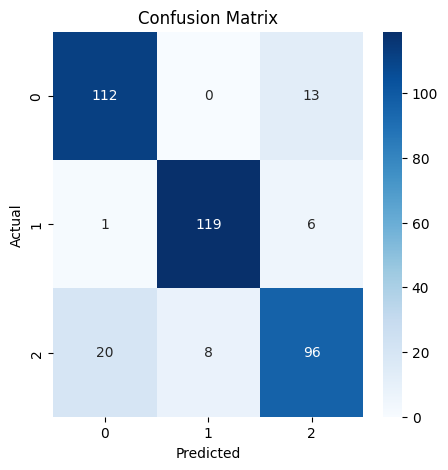

In [5]:
plt.figure(figsize=(5,5))
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt='d',cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [6]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87       125
           1       0.94      0.94      0.94       126
           2       0.83      0.77      0.80       124

    accuracy                           0.87       375
   macro avg       0.87      0.87      0.87       375
weighted avg       0.87      0.87      0.87       375



In [7]:
new_sample=np.array([[-1.5,-0.9,-1.0,1.4],[1.3,1.0,-1.2,-0.8],[-0.7,-1.4,1.6,1.1],[0.2,0.1,0.0,0.3]],ndmin=2)
new_type=model.predict(new_sample)
print(f'the sample types are {new_type}')

the sample types are [0 1 2 1]
